# Pencils down analysis
Contactomes

In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import csv
import pandas as pd
plt.rcParams['svg.fonttype'] = 'none'

In [2]:
def load_contactome(filename):
    df = pd.read_csv(filename)
    G = nx.from_pandas_edgelist(df, source='id1', target='id2', edge_attr='nm^2')
    return G

In [4]:
contactomes = []
start_checkpoint = 0
end_checkpoint = 45
for i in range(start_checkpoint, end_checkpoint+1, 5):
    contactomes.append(load_contactome(f"contactome-{i}k-100825.csv"))

In [5]:
original_edge_count = len(contactomes[0].edges())
original_node_count = len(contactomes[0].nodes())
contactome_edge_counts = [len(g.edges()) - original_edge_count for g in contactomes]
contactome_node_counts = [len(g.nodes()) - original_node_count for g in contactomes]


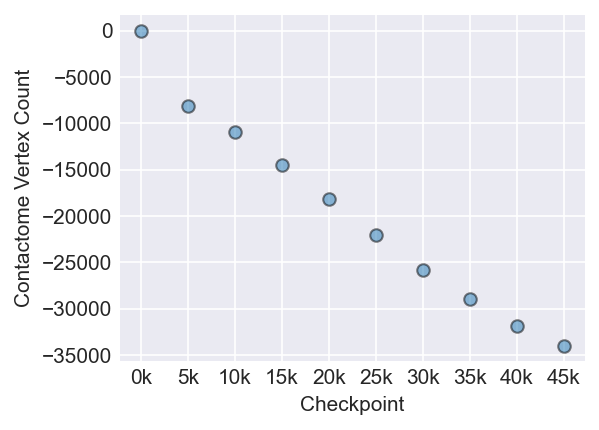

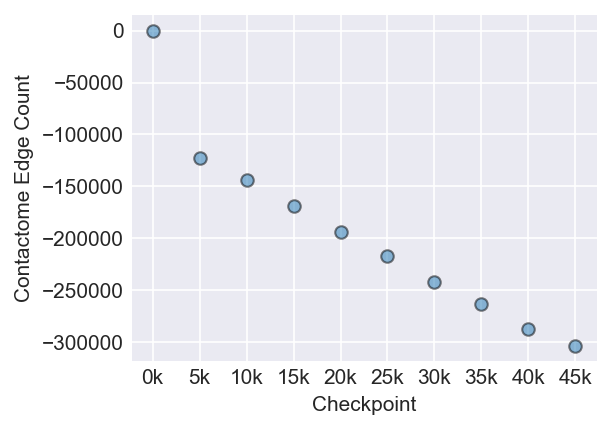

In [6]:
with plt.style.context("seaborn-v0_8-darkgrid"):
    plt.figure(figsize=(4,3), dpi=150)
    plt.scatter(
        [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
        [contactome_node_counts],
        alpha=0.5,
        edgecolors="k",
    )
    plt.xlabel("Checkpoint")
    plt.ylabel("Contactome Vertex Count")

    plt.figure(figsize=(4,3), dpi=150)
    plt.scatter(
        [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
        [contactome_edge_counts],
        alpha=0.5,
        edgecolors="k",
    )
    plt.xlabel("Checkpoint")
    plt.ylabel("Contactome Edge Count")


    plt.show()

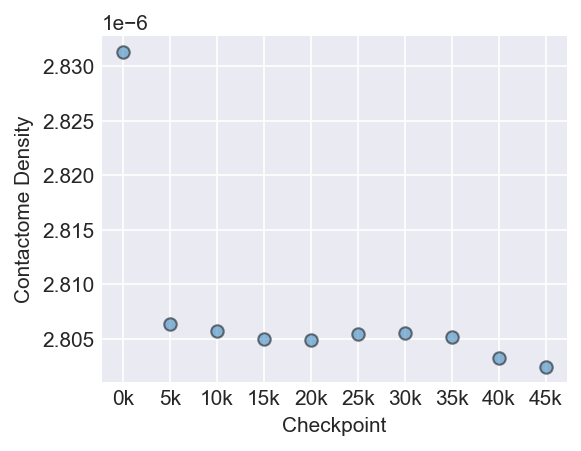

In [7]:
with plt.style.context("seaborn-v0_8-darkgrid"):
    plt.figure(figsize=(4,3), dpi=150)
    plt.scatter(
        [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
        [nx.density(g) for g in contactomes],
        alpha=0.5,
        edgecolors="k",
    )
    plt.xlabel("Checkpoint")
    plt.ylabel("Contactome Density")

    # This timed out. Need to recompute and import in.
    # plt.figure(figsize=(4,3), dpi=150)
    # plt.scatter(
    #     [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
    #     [nx.betweenness_centrality(g) for g in contactomes],
    #     alpha=0.5,
    #     edgecolors="k",
    # )
    # plt.xlabel("Checkpoint")
    # plt.ylabel("Contactome Betweenness Centrality")
    
    plt.show()

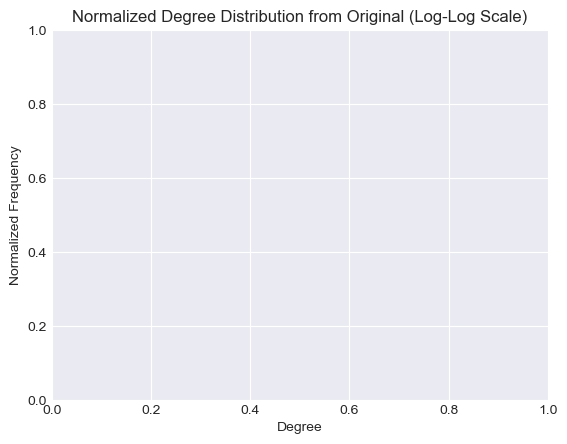

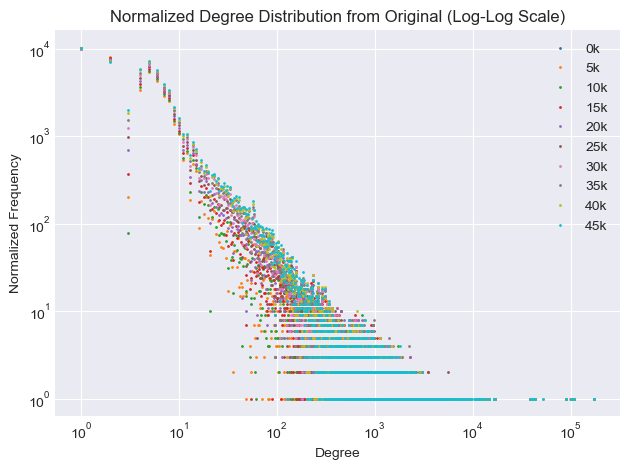

In [45]:
def create_yaxis(original_degree_freq, degree_freq):
    orig_len = len(original_degree_freq)
    new_len = len(degree_freq)
    num_to_pad = abs(orig_len - new_len)
    if orig_len > new_len:
        degree_freq = np.pad(degree_freq, (0,num_to_pad), "constant", constant_values=0)
    elif new_len > orig_len:
        original_degree_freq = np.pad(original_degree_freq, (0,num_to_pad), "constant", constant_values=0)
    return abs(original_degree_freq - degree_freq)

original_degree_freq = np.array(nx.degree_histogram(contactomes[0]))
with plt.style.context("seaborn-v0_8-darkgrid"):
    # fig, axes = plt.subplots(2, 5, figsize=(16,9))
    fig = plt.figure()
    plt.xlabel('Degree')
    plt.ylabel('Normalized Frequency')
    plt.title('Normalized Degree Distribution from Original (Log-Log Scale)')
    for i, contactome in enumerate(contactomes):
        degree_freq = np.array(nx.degree_histogram(contactome))
        yaxis = create_yaxis(original_degree_freq, degree_freq)
        xaxis = range(len(yaxis))
        plt.loglog(xaxis, yaxis, label=f"{i*5}k", linestyle='None', marker='o', markersize="1")
        # axes[0 if i < 5 else 1, i%5].loglog(xaxis, yaxis, label=f"{i*5}k", linestyle='None', marker='o', markersize="1")
        # axes[0 if i < 5 else 1, i%5].loglog(range(len(degree_freq)), degree_freq, label=f"{i*5}k", linestyle='None', marker='o', markersize="1")
        # axes[0 if i < 5 else 1, i%5].legend()
        plt.legend()
    plt.tight_layout()
    plt.show()